# Two channels, one cut
### Multi-touch attribution on 240,108 customer journeys

**The decision.** Next quarter's paid media budget is shrinking, and one channel's line item is going on the cut list. The last-click dashboard says the answer is obvious: Instagram and Online Display share last place, 0.6 points apart. Pick either.

**The question this notebook answers.** Is that tie real, or is it a side effect of how last-click hands out credit? If one of the two is doing more work than the dashboard shows, cutting it costs conversions nobody budgeted for.

**What's in here**
1. The data and how journeys are built
2. The last-click view that created the tie
3. Six attribution models on the same journeys
4. Why the models disagree (assist share, length-matched conversion lift)
5. How sure we can be (bootstrap confidence intervals)
6. What removing each channel would cost, and the recommendation

All logic lives in `src/mta/`; this notebook calls it and explains the results.

In [1]:
import sys, json
from pathlib import Path

import pandas as pd
from IPython.display import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from mta import (CHANNELS, HEURISTIC_MODELS, MarkovCells, aggregate_paths, assist_share,
                 bootstrap_data_driven, build_journeys, heuristic_attribution, length_matched_lift,
                 load_touchpoints, markov_attribution, shapley_attribution)
from mta.bootstrap import summarize

FIG = ROOT / "figures"
pct = lambda df, d=1: df.map(lambda v: f"{v:.{d}%}")

## 1. Data

`attribution_data.csv` is a public Kaggle dataset of ad touchpoints for one advertiser across five channels in July 2018. Each row is an impression or a conversion, tagged with a cookie (user), timestamp, and channel. Its origin isn't documented, so the findings below are a demonstration of method on realistic data, not facts about a real brand.

A **journey** is every interaction one cookie had, in time order. The conversion row carries its own channel, so it counts as the final touch. Identical paths are then collapsed, which turns 240K journeys into about 11K unique paths for the models to work on.

In [2]:
touch = load_touchpoints(ROOT / "data" / "attribution_data.csv")
journeys = build_journeys(touch)
paths = aggregate_paths(journeys)

print(f"Touchpoints   {len(touch):>9,}")
print(f"Journeys      {len(journeys):>9,}")
print(f"Unique paths  {len(paths):>9,}")
print(f"Conversions   {journeys.converted.sum():>9,}  ({journeys.converted.mean():.2%} of journeys)")
print(f"Value         ${journeys.value.sum():>8,.0f}")
print(f"Dates         {touch.time.min():%d %b %Y} to {touch.time.max():%d %b %Y}")

Touchpoints     586,737
Journeys        240,108
Unique paths     11,374
Conversions      17,639  (7.35% of journeys)
Value         $ 110,231
Dates         01 Jul 2018 to 31 Jul 2018


In [3]:
# Longer journeys convert more often. Keep this in mind: it confounds any
# "journeys with channel X convert better" comparison, so section 4 controls for it.
by_len = (journeys.assign(touches=journeys.length.clip(upper=6))
          .groupby("touches").agg(journeys=("converted", "size"), conversion_rate=("converted", "mean")))
by_len.index = [str(i) for i in by_len.index[:-1]] + ["6+"]
pd.DataFrame({
    "journeys": by_len.journeys.map("{:,}".format),
    "share of journeys": (by_len.journeys / by_len.journeys.sum()).map("{:.1%}".format),
    "conversion rate": by_len.conversion_rate.map("{:.1%}".format),
})

,journeys,share of journeys,conversion rate
1,"123,464",51.4%,6.0%
2,"51,880",21.6%,6.4%
3,"24,853",10.4%,7.8%
4,"13,106",5.5%,9.0%
5,"7,817",3.3%,10.3%
6+,"18,988",7.9%,15.6%


Half of all journeys are a single touch, and conversion rises from 6% at one touch to about 16% at six or more. That's normal: people who see more ads are often already more interested.

## 2. The last-click view

Most ad platforms and analytics defaults give 100% of the credit to the final touch before conversion.

In [4]:
last = heuristic_attribution(paths, "Last touch").sort_values(ascending=False)
pct(last.to_frame("last-touch share"))

,last-touch share
Facebook,30.1%
Paid Search,25.8%
Online Video,19.3%
Instagram,12.7%
Online Display,12.1%


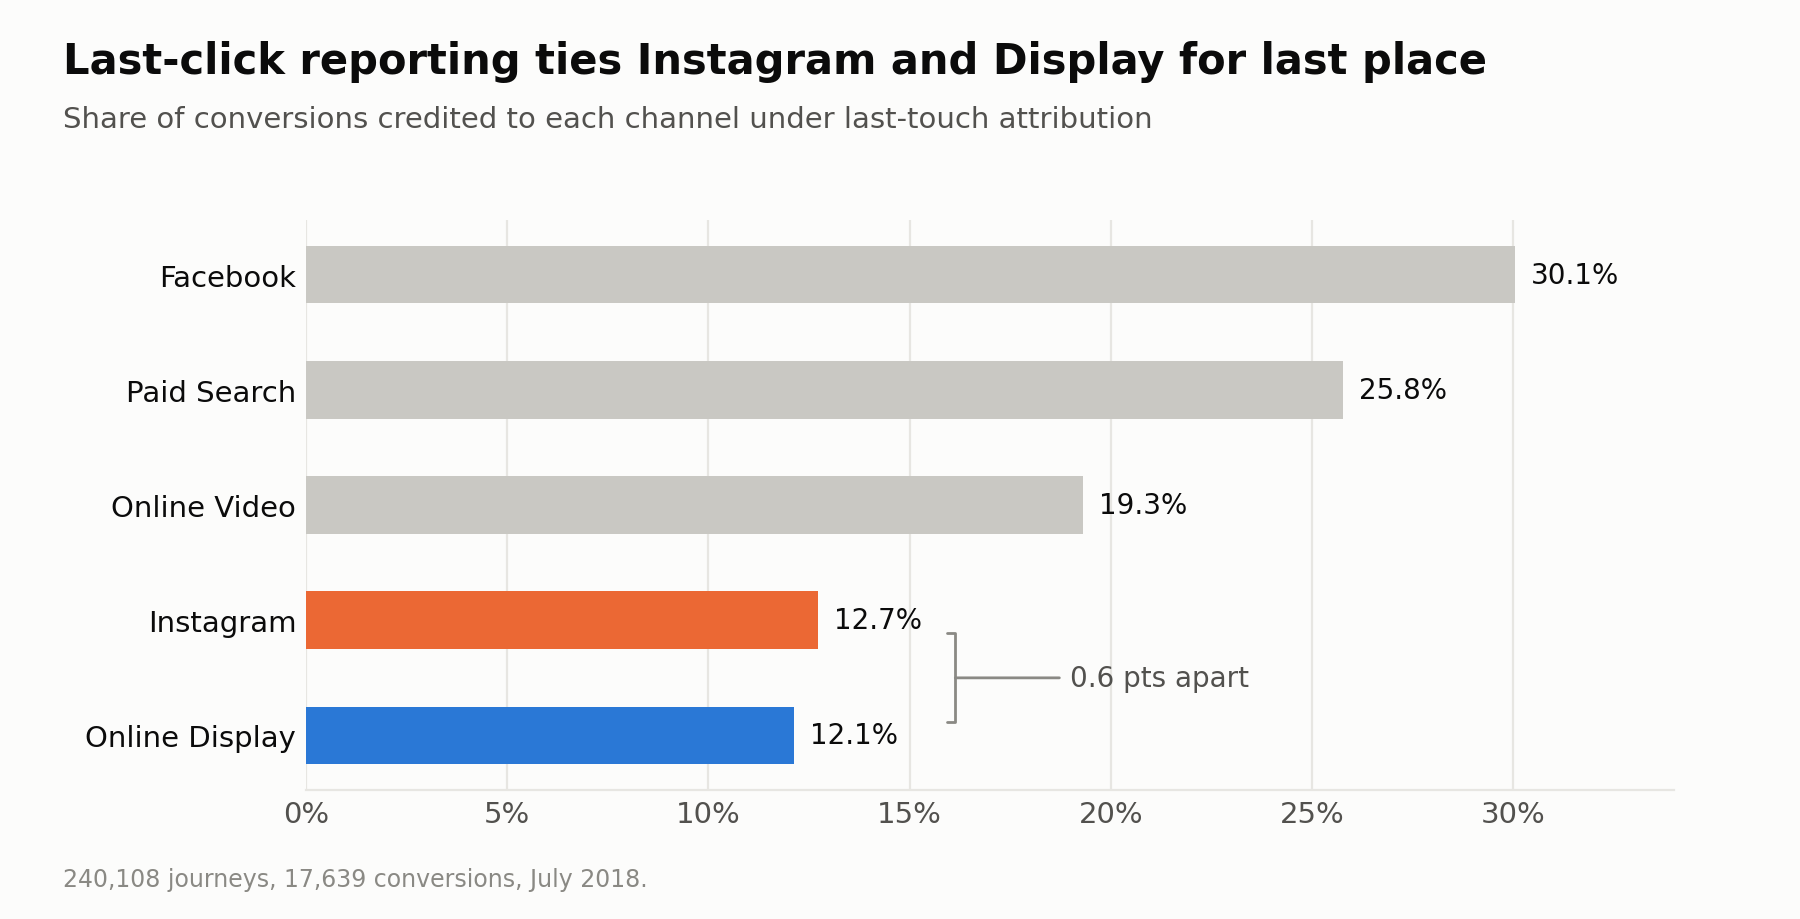

In [5]:
Image(FIG / "01_last_touch_tie.png")

Instagram (12.7%) and Online Display (12.1%) are effectively tied. On this view, cutting either one looks equally safe.

## 3. Six models, same journeys

| Type | Model | How credit is assigned |
|---|---|---|
| Rule-based | First touch | 100% to the first touch |
| | Last touch | 100% to the last touch |
| | Linear | Split equally across touches |
| | Position-based | 40% first, 40% last, 20% across the middle |
| Data-driven | **Markov removal effect** | Fit a transition model of how users move between channels; credit is how much the conversion probability falls when a channel is removed |
| | **Shapley value** | Each channel's average marginal contribution to conversions, across every possible combination of channels |

Rule-based models apply a fixed formula to position. The data-driven models learn credit from which journeys actually convert, which is why they're the ones that can disagree with the dashboard.

In [6]:
cells = MarkovCells(paths)
markov_share, removal = markov_attribution(paths, cells)
shares = pd.DataFrame({m: heuristic_attribution(paths, m) for m in HEURISTIC_MODELS})
shares["Markov"] = markov_share
shares["Shapley"] = shapley_attribution(paths)
pct(shares.loc[CHANNELS])

,First touch,Last touch,Linear,Position-based,Markov,Shapley
Facebook,29.3%,30.1%,29.6%,29.6%,29.8%,28.0%
Instagram,13.2%,12.7%,12.8%,12.9%,17.1%,14.9%
Online Display,12.2%,12.1%,12.0%,12.1%,12.0%,12.2%
Online Video,18.2%,19.3%,19.0%,18.8%,16.5%,18.1%
Paid Search,27.0%,25.8%,26.5%,26.4%,24.6%,26.8%


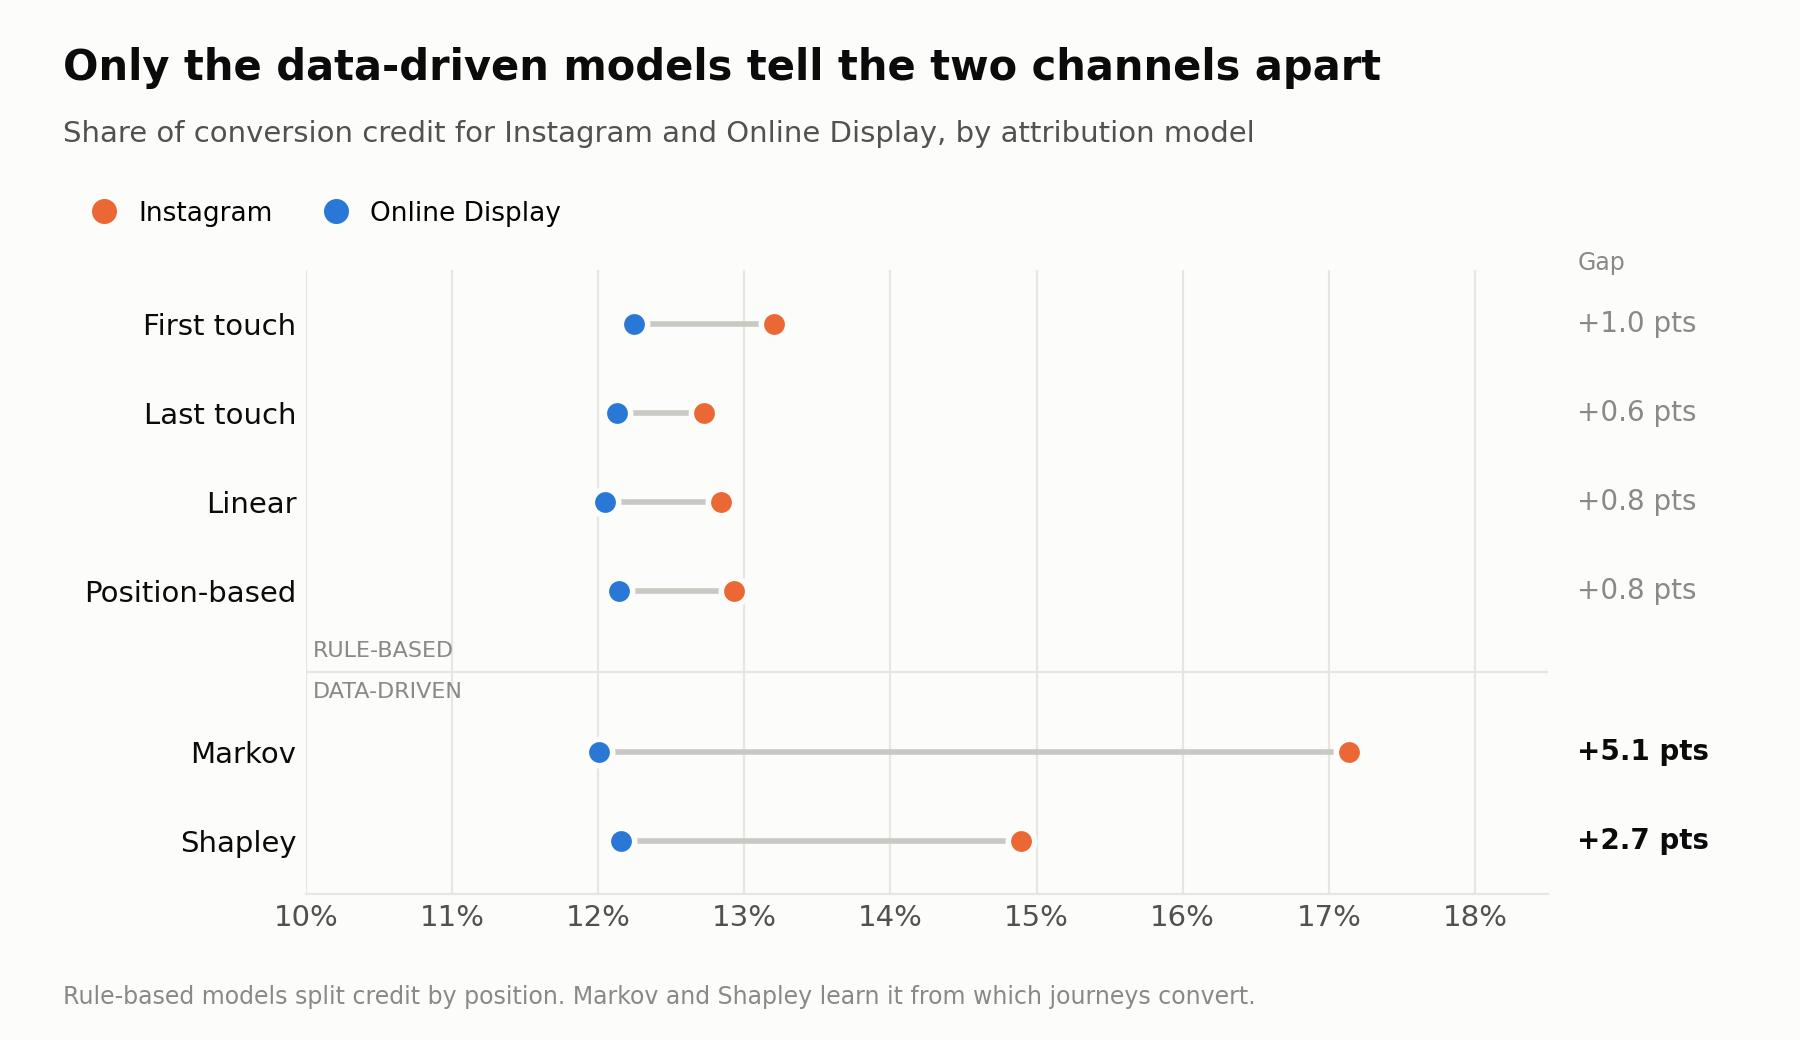

In [7]:
Image(FIG / "02_models_split_the_tie.png")

In [8]:
gap = (shares.loc["Instagram"] - shares.loc["Online Display"]).rename("Instagram minus Display")
gap.map(lambda v: f"{v * 100:+.1f} pts").to_frame()

,Instagram minus Display
First touch,+1.0 pts
Last touch,+0.6 pts
Linear,+0.8 pts
Position-based,+0.8 pts
Markov,+5.1 pts
Shapley,+2.7 pts


Every rule-based model keeps the tie (gaps of 0.6 to 1.0 points). Both data-driven models break it: Instagram earns **5.1 points more** than Display under Markov and **2.7 more** under Shapley. Display's credit barely moves under any model; Instagram's is what changes.

Two models built on different assumptions (Markov uses the order of touches, Shapley ignores order and looks only at which channels appear together) agree on the direction. Their size differs, which is expected: removal-effect methods are known to weight channels differently from Shapley when channels co-occur often.

## 4. Why the models disagree

Two checks that don't depend on any attribution model.

**Assist share.** Of converting journeys that include a channel, how often was it *not* the last touch? Last-click gives those journeys zero credit for the channel.

In [9]:
assist = assist_share(journeys)
pct(assist.sort_values("assisted_only", ascending=False), 0)

,in_converting_journeys,closed,assisted_only
channel,,,
Instagram,26%,49%,51%
Facebook,41%,73%,27%
Online Display,16%,74%,26%
Paid Search,34%,76%,24%
Online Video,22%,87%,13%


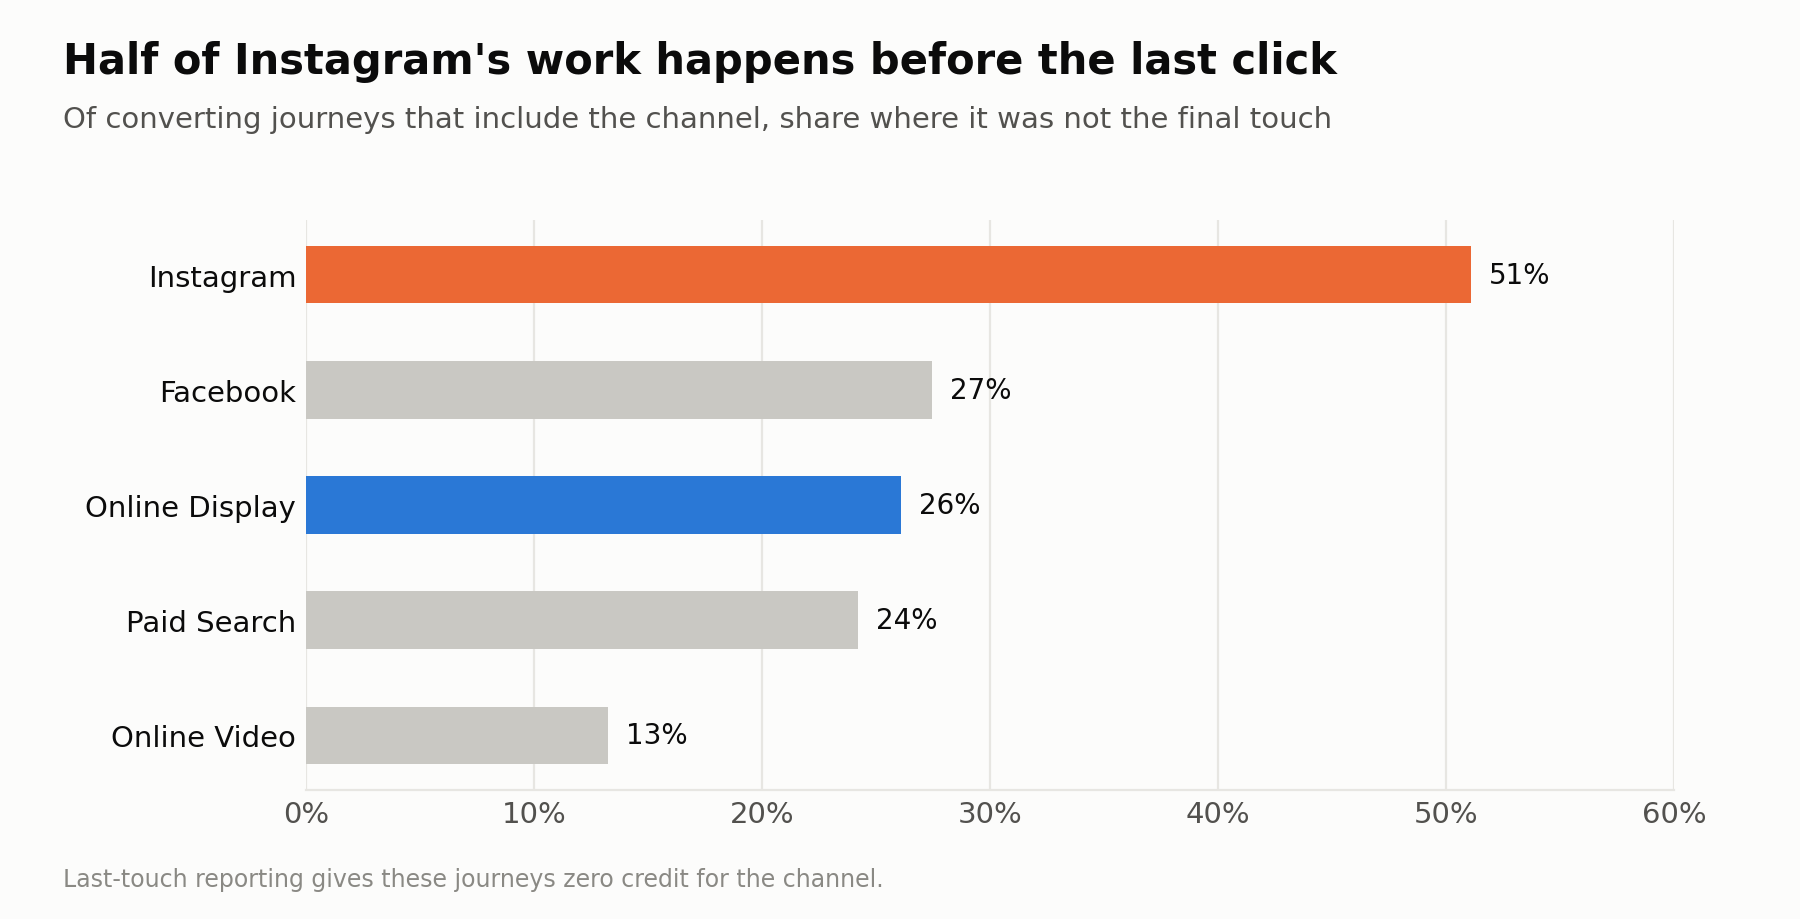

In [10]:
Image(FIG / "03_assist_share.png")

Instagram assists without closing in **51%** of the converting journeys it's part of, roughly double every other channel (13% to 27%). Last-click is blind to half of what Instagram does. Display looks like the other channels: when it's present, it usually *is* the last touch, so last-click already counts most of its contribution.

**Length-matched conversion lift.** Do journeys that include a channel convert better than journeys of the same length that don't? Matching on length removes the "longer journeys convert more" effect from section 1.

In [11]:
lift = length_matched_lift(journeys)
lift.index = [str(i) for i in lift.index[:-1]] + ["6+"]
lift.map(lambda v: f"{v:.2f}×")

,Facebook,Instagram,Online Display,Online Video,Paid Search
1,0.97×,1.01×,0.91×,1.14×,1.01×
2,1.11×,1.08×,0.97×,1.30×,0.87×
3,1.24×,1.20×,0.90×,1.22×,0.69×
4,1.07×,1.12×,0.80×,1.18×,0.75×
5,1.09×,1.17×,0.80×,1.18×,0.65×
6+,0.99×,1.03×,0.68×,1.18×,0.72×


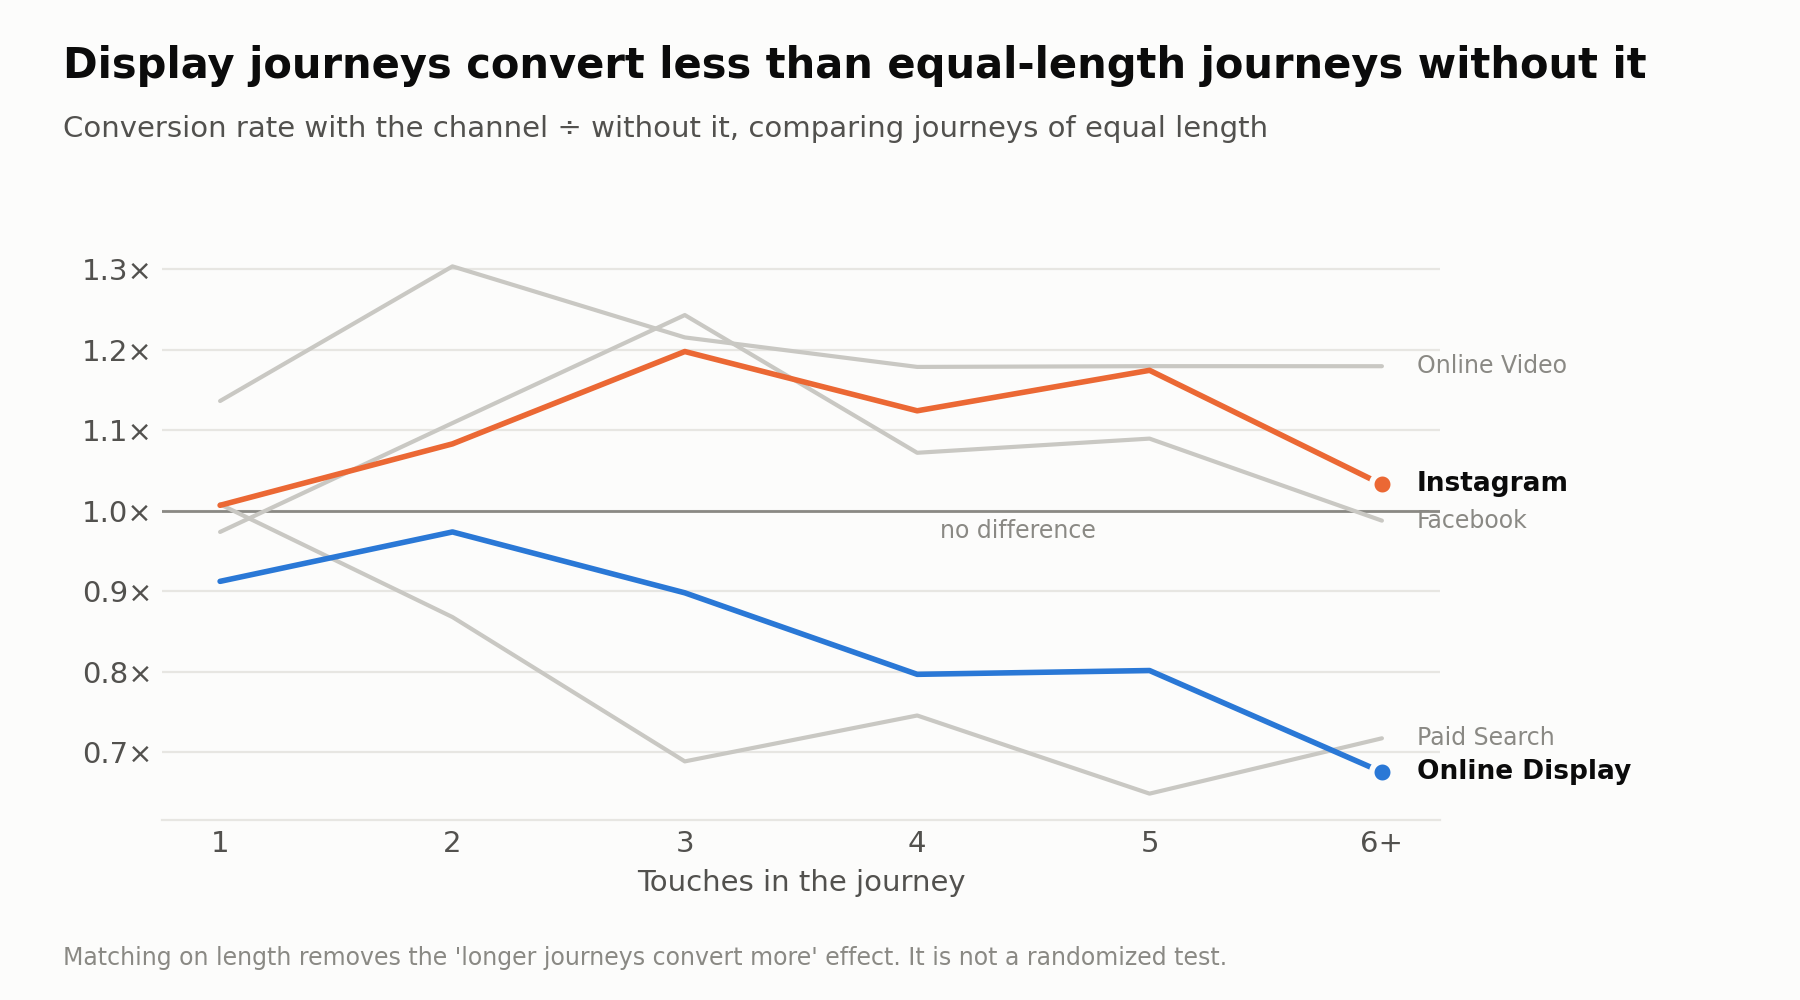

In [12]:
Image(FIG / "04_length_matched_lift.png")

At every length, journeys with Instagram convert at least as well as those without it (up to 1.2×). Journeys with Display convert *worse* at every length, falling to 0.68× for long journeys. Display shows up, but the journeys it shows up in tend not to finish.

This is a correlation, not a controlled experiment: Display could be bought against lower-intent audiences, for example. It's consistent with the model results, and section 6 says how to confirm it.

## 5. How sure can we be?

Resampling the 240K journeys with replacement 500 times and refitting both data-driven models gives a 95% interval for every number.

In [13]:
boot = bootstrap_data_driven(paths, n_boot=500, seed=7)
ci = summarize(boot)
table = pd.DataFrame({
    "Markov share": [f"{markov_share[c]:.1%}  ({ci.loc[c, ('low', 'markov_share')]:.1%}–{ci.loc[c, ('high', 'markov_share')]:.1%})" for c in CHANNELS],
    "Shapley share": [f"{shares.loc[c, 'Shapley']:.1%}  ({ci.loc[c, ('low', 'shapley_share')]:.1%}–{ci.loc[c, ('high', 'shapley_share')]:.1%})" for c in CHANNELS],
}, index=CHANNELS)
table

,Markov share,Shapley share
Facebook,29.8% (29.4%–30.1%),28.0% (27.5%–28.5%)
Instagram,17.1% (16.8%–17.4%),14.9% (14.5%–15.3%)
Online Display,12.0% (11.7%–12.3%),12.2% (11.7%–12.6%)
Online Video,16.5% (16.1%–16.9%),18.1% (17.6%–18.6%)
Paid Search,24.6% (24.2%–25.0%),26.8% (26.2%–27.3%)


In [14]:
wide = boot.pivot(index="replicate", columns="channel", values="markov_share")
g = wide["Instagram"] - wide["Online Display"]
wide_s = boot.pivot(index="replicate", columns="channel", values="shapley_share")
gs = wide_s["Instagram"] - wide_s["Online Display"]
print(f"Markov gap  (Instagram - Display): {g.mean()*100:.1f} pts, 95% CI {g.quantile(.025)*100:.1f} to {g.quantile(.975)*100:.1f}")
print(f"Shapley gap (Instagram - Display): {gs.mean()*100:.1f} pts, 95% CI {gs.quantile(.025)*100:.1f} to {gs.quantile(.975)*100:.1f}")
print(f"Replicates where Instagram > Display: Markov {(g > 0).mean():.0%}, Shapley {(gs > 0).mean():.0%}")

Markov gap  (Instagram - Display): 5.1 pts, 95% CI 4.6 to 5.6
Shapley gap (Instagram - Display): 2.7 pts, 95% CI 2.0 to 3.4
Replicates where Instagram > Display: Markov 100%, Shapley 100%


Neither interval comes close to zero. With this much data, sampling noise is not the risk. The real risks are the modelling assumptions, covered in section 7.

## 6. What removing each channel would cost

The Markov removal effect answers the budget question directly: if this channel disappeared and everyone who would have reached it dropped out instead, how many conversions would the model expect to lose?

In [15]:
n_conv = journeys.converted.sum()
cost = pd.DataFrame({
    "removal effect": removal,
    "conversions at risk": (removal * n_conv).round(0).astype(int),
    "value at risk ($)": (removal * journeys.value.sum()).round(0).astype(int),
}).loc[CHANNELS].sort_values("removal effect")
pd.DataFrame({
    "removal effect": cost["removal effect"].map("{:.1%}".format),
    "conversions at risk": cost["conversions at risk"].map("{:,}".format),
    "value at risk": cost["value at risk ($)"].map("${:,}".format),
})

,removal effect,conversions at risk,value at risk
Online Display,16.7%,"2,944","$18,397"
Online Video,22.9%,"4,046","$25,287"
Instagram,23.8%,"4,202","$26,257"
Paid Search,34.1%,"6,022","$37,632"
Facebook,41.4%,"7,301","$45,629"


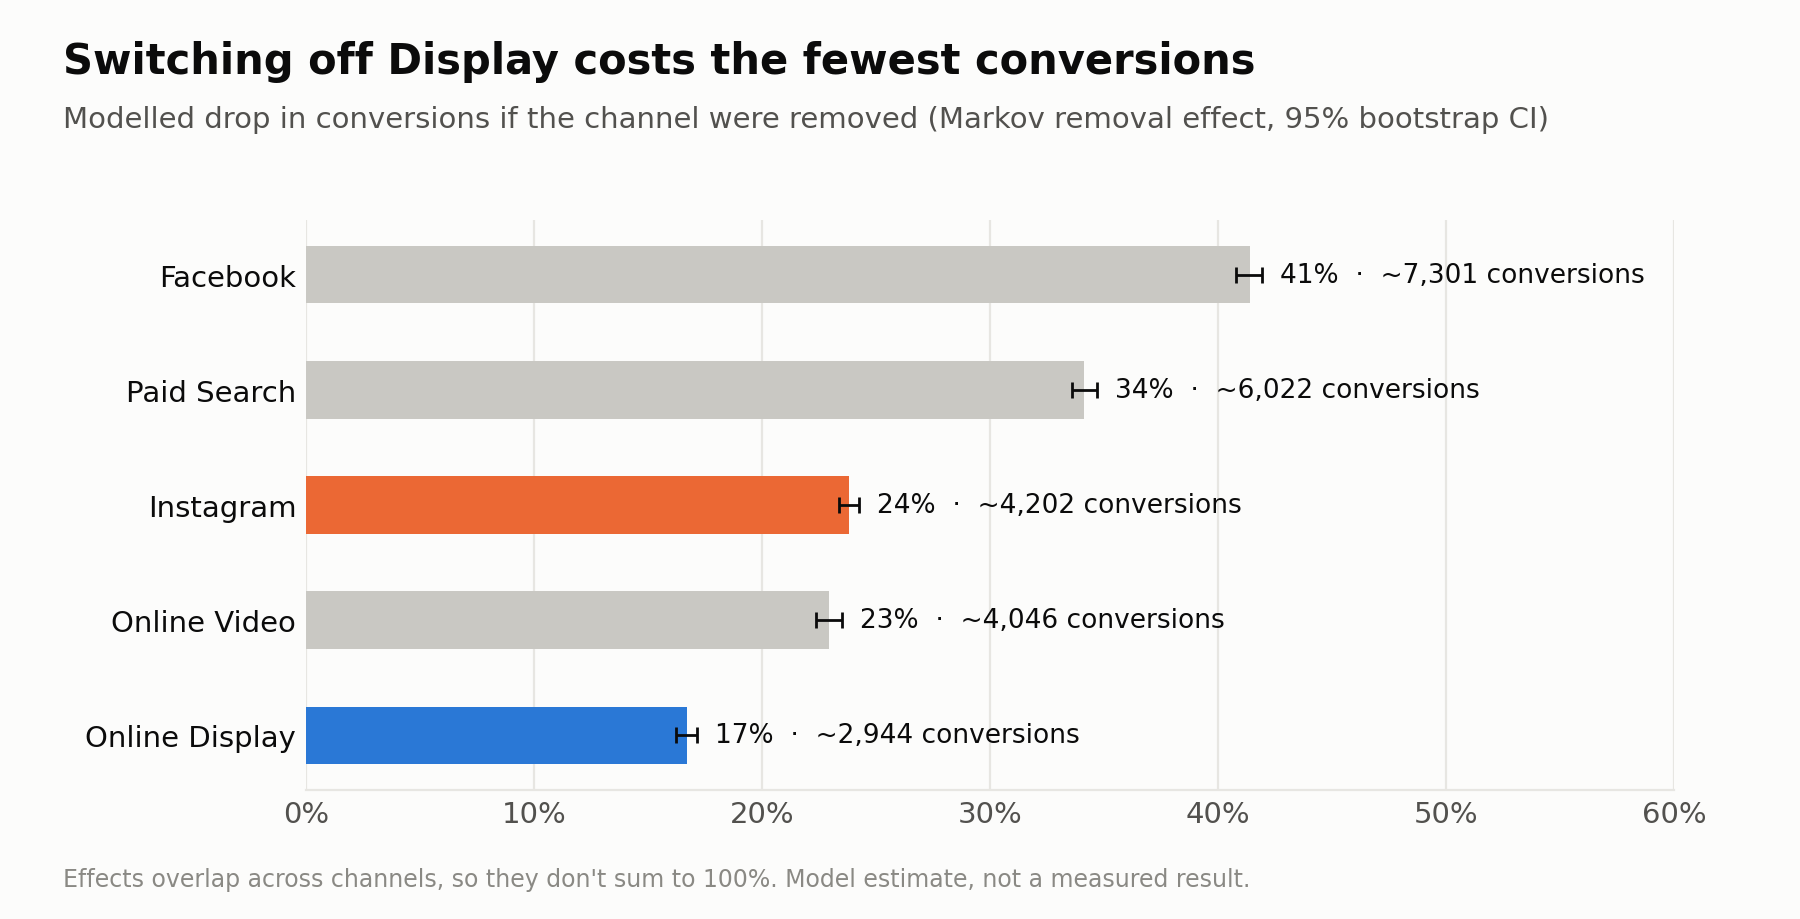

In [16]:
Image(FIG / "05_removal_effect.png")

Removing Display costs about **2,900** conversions in the model; removing Instagram costs about **4,200**, roughly 1,250 more for a channel the dashboard ranks the same. Removal effects overlap (a conversion can depend on two channels), so they don't add to 100% and are best read as upper bounds.

## Recommendation

1. **Put Online Display on the cut list, not Instagram.** Every view points the same way: lowest removal effect, flat credit under every model, and lower conversion in the journeys it touches.
2. **Don't cut Display blind; test the cut.** Run a geo holdout: pause Display in a matched set of regions for 4–6 weeks and compare total conversions against control regions. The model's upper-bound prediction is a drop of about 17% in total conversions in the paused regions; the test says how much of that is real.
3. **Stop judging Instagram on last-click.** Report it on Markov credit, or at minimum alongside its assist share. On last-click it will keep looking like a cut candidate.

## 7. Limits

- **No cost data.** The file has no spend, so this ranks channels by contribution, not return. With spend, the cut should be ranked by conversions lost per dollar saved.
- **Observational.** Attribution models describe which paths convert; they don't prove a channel caused the conversion. That's why step 2 is a test.
- **First-order Markov.** The model assumes the next step depends only on the current channel. Higher-order chains are a natural extension.
- **One month, one advertiser, undocumented source.** Treat the specific numbers as a worked example; the method transfers.

In [17]:
# Everything in the README and case study comes from these files, written by run_analysis.py.
print(json.dumps(json.loads((ROOT / "results" / "headline.json").read_text()), indent=2))

{
  "touchpoints": 586737,
  "journeys": 240108,
  "unique_paths": 11374,
  "conversions": 17639,
  "conversion_rate": 0.07346277508454528,
  "conversion_value": 110231.0,
  "date_min": "2018-07-01",
  "date_max": "2018-07-31",
  "single_touch_share": 0.5142019424592267,
  "median_path_length": 1.0,
  "last_touch_gap_ig_minus_display": 0.005953,
  "markov_gap_ig_minus_display": 0.051303000000000015,
  "markov_gap_ci": [
    0.04631607308060326,
    0.056402282688511864
  ],
  "markov_gap_prob_positive": 1.0,
  "shapley_gap_ig_minus_display": 0.02741100000000002,
  "shapley_gap_ci": [
    0.0203120816931704,
    0.034038649642740205
  ],
  "bootstrap_replicates": 500
}
